# EQG vs Qiskit best-effort — validación del conjunto completo (CPU/Aer → decisión QPU)

Pregunta: **¿EQG completo (Ojos → Juicio → Reflejos → Manos) aporta valor por encima de lo que Qiskit ya da gratis?**

| Brazo | Qué es |
|---|---|
| **naive** | Layout por defecto `[0..N-1]`, sin DD. Solo **referencia de estrés** (valida que el sistema "sangra"). |
| **qiskit** (OFF real) | `optimization_level=3` con Target de errores (layout noise-aware, calibración publicada/obsoleta) + DD estándar en todo el layout |
| **eqg** (ON) | Telemetría viva → Juicio → layout por fricción (Reflejos) → DD selectivo por fricción (Manos) |

Sin ablaciones: el ON es el producto entero. La ganancia se mide **contra `qiskit`**, no contra `naive`.

| Compuerta | Pregunta |
|---|---|
| `ERROR_COMPILACION` | ¿Los 3 brazos compilan al *mismo cálculo*? (base de puertas, layout, SWAPs, DD par, equivalencia sin ruido) |
| `PRUEBA_NO_VALIDA` | ¿NAIVE(T5) cae en 0.60–0.75 (sin techo ni piso)? ¿El brazo Qiskit fue de verdad noise-aware? |
| `PRODUCTO_OK` | ¿EQG > Qiskit best-effort con z ≥ 2 y Δ ≥ 0.03 en cada semilla, en T1 y T5? |
| `QPU_READY` | Todo lo anterior + ganancia agregada significativa |

Un resultado `PRODUCTO_NO` por **paridad** es información válida: significa que Qiskit ya captura el beneficio en este escenario.


## 0. Config


In [1]:
# ============================================================
# CONFIG — fijar ANTES de mirar resultados; no retocar umbrales tras ver ON
# ============================================================
MODE = "cpu"                 # "cpu" (Aer, barrido de semillas) | "qpu" (una sola corrida, hardware)
BACKEND_NAME = "ibm_fez"
QPU_CONFIRM = False
MAX_QPU_SECONDS = 300.0

EQG_VERSION = "EQG-1.3.0"

# --- Criterios de decisión ---
BAND_LO, BAND_HI = 0.60, 0.75   # banda operativa exigida al brazo NAIVE (T5): régimen de estrés real
QISKIT_OPT_LEVEL = 3             # brazo OFF "Qiskit best-effort": layout noise-aware + DD estándar
ARMS = ("naive", "qiskit", "eqg")
Z_MIN = 2.0                      # z mínimo de la ganancia ON−OFF
MIN_DELTA = 0.03                 # ganancia mínima material en HIS (evita z grande con efecto trivial)
MIN_CYCLES_PER_ARM = 4
INTEG_TOL = 0.01                 # tolerancia de equivalencia sin ruido (en unidades de HIS) + 4·SE

# --- Carga ---
if MODE == "cpu":
    SEEDS = [42, 7]          # distintos dispositivos / qubits malos / Hamiltoniano T5 / parámetros
    N_LOGICAL = 10
    QAOA_P = 6
    HEA_LAYERS = 5
    HEA_SIGMA = 0.12
    IDLE_US = 8.0
    SHOTS = 8192
    N_CYCLES = 4             # 4 ciclos por brazo (mínimo exigido); con 6 y K=8 cada semilla tardó ~17 min
    K_REAL = 4               # realizaciones de desintonía cuasi-estática por circuito
    ID_UNIT_US = 2.0         # 1 puerta 'id' (relajación térmica de 2 µs) por cada 2 µs de idle
    # gate_x escala errores de CX/1q/lectura; idle_x escala 1/T1, 1/T2 y desintonía.
    # Calibrados (simulador sustituto) para NAIVE(T5) ≈ 0.65 — se re-verifica con la banda.
    SIM = dict(M=26, bad_in_layout=6, bad_tail=2,
               delta_good=0.04, delta_bad=0.45, jitter=0.25,
               stale_flip=0.22, time_drift=0.12,
               cx_good=0.012, cx_bad=0.018,
               om_good=0.03, om_bad=0.12,                 # rad/µs (1σ cuasi-estática)
               t1_good=200.0, t2_good=150.0,              # µs
               t1_bad=80.0, t2_bad=50.0,                  # µs (qubits con TLS)
               gate_x=0.40, idle_x=0.25)
else:
    SEEDS = [42]
    N_LOGICAL = 8
    QAOA_P = 3
    HEA_LAYERS = 4
    HEA_SIGMA = 0.12
    IDLE_US = 5.0
    SHOTS = 1024
    N_CYCLES = 2
    K_REAL = 1
    ID_UNIT_US = 2.0
    SIM = {}

# --- Política de fricción (Reflejos + Manos) ---
DD_AGGR = 0.0                # DD si fr ≥ lo + DD_AGGR·(hi−lo)
DD_MIN_FRAC = 0.6            # ≥ 60 % de los qubits del layout reciben DD
ABORT_FR_MEAN = 0.90

OUT_DIR = f"eqg_on_off_{MODE}"
print("EQG_VERSION", EQG_VERSION, "| MODE", MODE, "| seeds", SEEDS)
print("N", N_LOGICAL, "p", QAOA_P, "HEA", HEA_LAYERS, "idle_us", IDLE_US, "shots", SHOTS, "cycles", N_CYCLES, "K", K_REAL)
print("OUT", OUT_DIR)


EQG_VERSION EQG-1.3.0 | MODE cpu | seeds [42, 7]
N 10 p 6 HEA 5 idle_us 8.0 shots 8192 cycles 4 K 4
OUT eqg_on_off_cpu


## 1. Install & imports


In [2]:
%pip install -q "qiskit>=1.3" "qiskit-aer>=0.14" "qiskit-ibm-runtime>=0.30" numpy scipy pandas matplotlib

import json, math, time, gc, hashlib
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler import CouplingMap
from qiskit.transpiler import PassManager, InstructionDurations
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling
from qiskit.circuit.library import XGate, RZGate, SXGate, CXGate
from qiskit.circuit import Parameter, Delay, Measure
from qiskit.transpiler import Target, InstructionProperties
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (NoiseModel, depolarizing_error, ReadoutError,
                              thermal_relaxation_error)

OUT = Path(OUT_DIR); OUT.mkdir(parents=True, exist_ok=True)
EPS = 1e-8
N = N_LOGICAL

def mem_mb():
    try:
        import resource
        return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    except Exception:
        return float("nan")

FP = hashlib.sha256(json.dumps(dict(
    v=EQG_VERSION, mode=MODE, seeds=SEEDS, N=N, p=QAOA_P, hea=HEA_LAYERS, sig=HEA_SIGMA,
    idle=IDLE_US, shots=SHOTS, cycles=N_CYCLES, K=K_REAL, aggr=DD_AGGR, minfrac=DD_MIN_FRAC,
    band=(BAND_LO, BAND_HI), zmin=Z_MIN, mind=MIN_DELTA, opt=QISKIT_OPT_LEVEL, sim=SIM
), sort_keys=True, default=str).encode()).hexdigest()[:16]
print("OK | RSS≈%.0f MB | fp=%s" % (mem_mb(), FP))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 79.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 42.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 

## 2. HIS, Hamiltonianos y estimador (con piso de HIS verificado)


In [3]:
def his_span(h_id, h_re, span):
    return 1.0 - abs(h_id - h_re) / max(span, EPS)

def z_diff(a, sa, b, sb):
    s = math.sqrt(sa**2 + sb**2)
    return float("nan") if s < EPS else (a - b) / s

def plabel(n, ops):
    s = ["I"] * n
    for q, l in ops.items():
        s[n - 1 - q] = l
    return "".join(s)

def maxcut_path_H(n):
    t = [("I" * n, 0.5 * (n - 1))]
    t += [(plabel(n, {i: "Z", i + 1: "Z"}), -0.5) for i in range(n - 1)]
    return SparsePauliOp.from_list(t)

def hard_pauli_H(n, seed):
    # T5: cadena ferromagnética en X (XX + campo X) con acoplos YY/ZZ, campos Y/Z y términos mixtos Z·Y.
    rng = np.random.default_rng(seed)
    acc = defaultdict(float)
    for i in range(n - 1):
        acc[plabel(n, {i: "X", i + 1: "X"})] += -(1.0 + 0.10 * rng.normal())
        acc[plabel(n, {i: "Y", i + 1: "Y"})] += float(rng.normal(0, 0.30))
        acc[plabel(n, {i: "Z", i + 1: "Z"})] += float(rng.normal(0, 0.30))
    for i in range(n):
        acc[plabel(n, {i: "X"})] += -(0.40 + 0.05 * rng.normal())
        acc[plabel(n, {i: "Y"})] += float(rng.normal(0, 0.15))
        acc[plabel(n, {i: "Z"})] += float(rng.normal(0, 0.15))
    for i in range(0, n - 2, 2):
        acc[plabel(n, {i: "X", i + 2: "X"})] += -(0.30 + 0.05 * rng.normal())
        acc[plabel(n, {i: "Z", i + 1: "Y"})] += float(rng.normal(0, 0.15))
    return SparsePauliOp.from_list(list(acc.items())).simplify()

def qaoa_prep(n, p, gammas, betas, idle_fn=None):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for layer in range(p):
        for i in range(n - 1):
            qc.cx(i, i + 1)
            qc.rz(-2 * gammas[layer], i + 1)
            qc.cx(i, i + 1)
        if idle_fn:
            idle_fn(qc)
        qc.rx(2 * betas[layer], range(n))
        if idle_fn:
            idle_fn(qc)
    return qc

def hea_prep(n, layers, params, idle_fn=None):
    qc = QuantumCircuit(n)
    for L in range(layers):
        for q in range(n):
            qc.ry(float(params[L, q, 0]), q)
            qc.rz(float(params[L, q, 1]), q)
            qc.rx(float(params[L, q, 2]), q)
        for i in range(n - 1):
            qc.cx(i, i + 1)
        for i in range(n - 2, -1, -1):
            qc.cx(i + 1, i)
        if idle_fn:
            idle_fn(qc)
    return qc

def near_plus_params(layers, n, sigma, seed):
    # capa 0: ry(π/2) → |+>^n (invariante bajo la escalera de CX); resto: perturbaciones pequeñas.
    rng = np.random.default_rng(seed)
    P = rng.normal(0.0, sigma, size=(layers, n, 3))
    P[0] = 0.0
    P[0, :, 0] = np.pi / 2
    return P

def h_ideal(prep, H):
    return float(np.real(Statevector.from_instruction(prep).expectation_value(H)))

def spectrum_span(H):
    ev = np.linalg.eigvalsh(H.to_matrix())
    return float(ev[-1] - ev[0])

def h_mix(H):
    return float(np.real(H.to_matrix(sparse=True).diagonal().sum())) / (2 ** H.num_qubits)

def his_floor(h_id, hmix, span):
    return 1.0 - abs(h_id - hmix) / max(span, EPS)

def qwc_groups(H, n):
    """Agrupación qubit-wise commuting; basis[q] ∈ {X,Y,Z} (rotación por qubit, sin sesgo)."""
    terms = [(l, float(np.real(w))) for l, w in zip(H.paulis.to_labels(), H.coeffs)]
    ident = [(l, w) for l, w in terms if set(l) == {"I"}]
    rest = sorted([(l, w) for l, w in terms if set(l) != {"I"}], key=lambda x: -abs(x[1]))
    groups = []
    for l, w in rest:
        for g in groups:
            if all(ch == "I" or g["b"][i] in ("I", ch) for i, ch in enumerate(l)):
                for i, ch in enumerate(l):
                    if ch != "I":
                        g["b"][i] = ch
                g["items"].append((l, w))
                break
        else:
            groups.append(dict(b=list(l), items=[(l, w)]))
    if not groups:
        groups = [dict(b=["Z"] * n, items=[])]
    groups[0]["items"] += ident
    out = []
    for g in groups:
        basis = {n - 1 - i: ("Z" if c == "I" else c) for i, c in enumerate(g["b"])}
        out.append(dict(basis=basis, op=SparsePauliOp.from_list(g["items"])))
    return out

def group_stats(counts, op, n):
    labels = op.paulis.to_labels()
    coeffs = np.real(op.coeffs)
    vals, cnt = [], []
    for bs, c in counts.items():
        s = bs.replace(" ", "")[-n:].zfill(n)
        e = 0.0
        for lab, w in zip(labels, coeffs):
            par = 0
            for i, ch in enumerate(lab):
                if ch != "I" and s[i] == "1":
                    par ^= 1
            e += w * (1 - 2 * par)
        vals.append(e); cnt.append(c)
    cnt = np.asarray(cnt, float)
    shots = max(cnt.sum(), 1.0)
    return np.asarray(vals), cnt / shots, int(shots)

def estimate_energy(gcounts, gops, n):
    h, var = 0.0, 0.0
    for counts, op in zip(gcounts, gops):
        v, p, shots = group_stats(counts, op, n)
        m = float(p @ v)
        h += m
        var += float(p @ (v ** 2) - m ** 2) / max(shots, 1)
    return h, math.sqrt(max(var, 0.0))

# --- T1 (QAOA MaxCut): mismo Hamiltoniano para todas las semillas; parámetros optimizados UNA vez ---
_rng_t1 = np.random.default_rng(12345)
H1 = maxcut_path_H(N)
def _neg_e(x):
    return -h_ideal(qaoa_prep(N, QAOA_P, x[:QAOA_P], x[QAOA_P:]), H1)
_best = None
for _ in range(4):
    x0 = np.r_[_rng_t1.uniform(0.15, 1.1, QAOA_P), _rng_t1.uniform(0.08, 0.55, QAOA_P)]
    r = minimize(_neg_e, x0, method="COBYLA", options=dict(maxiter=250))
    if _best is None or r.fun < _best.fun:
        _best = r
GAMMAS, BETAS = _best.x[:QAOA_P].copy(), _best.x[QAOA_P:].copy()
_span1 = spectrum_span(H1)
_hid1 = h_ideal(qaoa_prep(N, QAOA_P, GAMMAS, BETAS), H1)
T1_ENTRY = dict(H=H1, h_id=_hid1, span=_span1, mix=h_mix(H1), groups=qwc_groups(H1, N), kind="qaoa")
T1_ENTRY["floor"] = his_floor(T1_ENTRY["h_id"], T1_ENTRY["mix"], T1_ENTRY["span"])
print("T1 QAOA p=%d h_id=%.3f span=%.3f groups=%d PISO_HIS=%.3f" % (
    QAOA_P, T1_ENTRY["h_id"], T1_ENTRY["span"], len(T1_ENTRY["groups"]), T1_ENTRY["floor"]))

def build_t5(seed):
    """T5 por semilla: HEA profundo cerca de |+>^n; Hamiltoniano con mayor profundidad |h_id−h_mix|/span."""
    P = near_plus_params(HEA_LAYERS, N, HEA_SIGMA, seed)
    best_H, best_depth = None, -1.0
    for s in range(30):
        H = hard_pauli_H(N, seed * 1000 + s)
        span = spectrum_span(H)
        if span < 1e-6:
            continue
        hid = h_ideal(hea_prep(N, HEA_LAYERS, P), H)
        depth = abs(hid - h_mix(H)) / span
        if depth > best_depth:
            best_depth, best_H = depth, H
    span5 = spectrum_span(best_H)
    hid5 = h_ideal(hea_prep(N, HEA_LAYERS, P), best_H)
    d = dict(H=best_H, h_id=hid5, span=span5, mix=h_mix(best_H),
             groups=qwc_groups(best_H, N), kind="hea", params=P)
    d["floor"] = his_floor(d["h_id"], d["mix"], d["span"])
    return d

# comprobación de diseño con la primera semilla.
# La banda 0.60–0.75 se exige al OFF de T5 (métrica primaria) → su piso DEBE quedar claramente por debajo.
# T1 es secundario: solo se advierte si su piso deja poco margen para degradarse.
_t5 = build_t5(SEEDS[0])
print("T5 HEA L=%d h_id=%.3f span=%.3f groups=%d PISO_HIS=%.3f" % (
    HEA_LAYERS, _t5["h_id"], _t5["span"], len(_t5["groups"]), _t5["floor"]))
if _t5["floor"] > BAND_LO - 0.03:
    raise RuntimeError("T5: piso de HIS %.3f no deja OFF en [%.2f, %.2f] — rediseñar Hamiltoniano/estado" % (
        _t5["floor"], BAND_LO, BAND_HI))
if T1_ENTRY["floor"] > BAND_HI - 0.10:
    print("AVISO: T1 piso %.3f deja poco margen de degradación; T1 no está sujeto a la banda (solo T5)." % T1_ENTRY["floor"])


T1 QAOA p=6 h_id=8.164 span=9.000 groups=1 PISO_HIS=0.593
T5 HEA L=5 h_id=-12.356 span=23.002 groups=5 PISO_HIS=0.463


## 3. Dispositivo simulado, circuitos compilados, Manos (DD) y ejecución


In [4]:
SIM_BASIS = ["rz", "sx", "x", "cx", "measure", "delay", "id", "barrier"]
_UNIT_US = {"s": 1e6, "ms": 1e3, "us": 1.0, "ns": 1e-3, "dt": 1e-3}

def friction_from_cal(cal, n_phys):
    fr = np.zeros(n_phys)
    for q in range(n_phys):
        ro = float(cal.get(q, {}).get("ro", 0.02))
        xe = float(cal.get(q, {}).get("xerr", 0.001))
        fr[q] = min(1.0, 6.0 * ro + 60.0 * xe)
    return fr

def two_means_thr(x):
    """Separa fricción 'limpia' vs 'mala' (k-means 1D, k=2) → (umbral_medio, centro_limpio, centro_malo)."""
    x = np.sort(np.asarray(x, float))
    lo, hi = float(x[0]), float(x[-1])
    for _ in range(100):
        thr = (lo + hi) / 2
        a, b = x[x <= thr], x[x > thr]
        if len(a) == 0 or len(b) == 0:
            break
        nlo, nhi = float(a.mean()), float(b.mean())
        if abs(nlo - lo) + abs(nhi - hi) < 1e-10:
            lo, hi = nlo, nhi
            break
        lo, hi = nlo, nhi
    return (lo + hi) / 2, lo, hi

class SimDevice:
    def __init__(self, M, bad_in_layout, bad_tail, delta_good, delta_bad, jitter,
                 stale_flip, time_drift, cx_good, cx_bad, om_good, om_bad,
                 t1_good, t2_good, t1_bad, t2_bad, gate_x, idle_x, seed=0):
        self.M, self.rng = M, np.random.default_rng(seed)
        inside = self.rng.choice(N_LOGICAL, size=bad_in_layout, replace=False).tolist()
        self.bad = set(inside) | set(range(M - bad_tail, M))
        self.stale_flip, self.time_drift, self.jitter = stale_flip, time_drift, jitter
        self.delta_good, self.delta_bad = delta_good, delta_bad
        self.cx_good, self.cx_bad = cx_good, cx_bad
        self.t1_good, self.t2_good, self.t1_bad, self.t2_bad = t1_good, t2_good, t1_bad, t2_bad
        self.gate_x, self.idle_x = gate_x, idle_x
        self.omega = np.array([(om_bad if q in self.bad else om_good) * idle_x for q in range(M)])
        self.cal = self._mk(True)
        self.live = self._mk(False)

    def _mk(self, stale):
        cal = {}
        for q in range(self.M):
            d = self.delta_bad if q in self.bad else self.delta_good
            j = math.exp(self.jitter * self.rng.normal())
            ro = (0.012 + d * 0.06) * j
            xe = (0.0006 + d * 0.0025) * j
            if stale:
                ro *= 1 + self.stale_flip * self.rng.random()
                xe *= 1 + self.stale_flip * self.rng.random()
            cal[q] = dict(ro=ro, xerr=xe)
        return cal

    def step(self):
        for q in range(self.M):
            scale = 1.15 if q in self.bad else 1.0
            d = 1.0 + self.time_drift * scale * self.rng.normal(0, 1) * 0.12
            self.live[q]["ro"] = min(0.25, max(1e-4, self.live[q]["ro"] * abs(d)))
            self.live[q]["xerr"] = min(0.08, max(1e-5, self.live[q]["xerr"] * abs(d)))
            self.omega[q] *= abs(1.0 + 0.10 * self.rng.normal())

    def noise_model(self):
        nm = NoiseModel()
        gx = self.gate_x
        for q in range(self.M):
            bad = q in self.bad
            ro = min(0.4, self.live[q]["ro"] * gx)
            nm.add_readout_error(ReadoutError([[1 - ro, ro], [ro, 1 - ro]]), [q])
            xe = min(0.5, 3 * self.live[q]["xerr"] * gx)
            nm.add_quantum_error(depolarizing_error(xe, 1), ["x", "sx"], [q])
            t1 = (self.t1_bad if bad else self.t1_good) / self.idle_x
            t2 = min((self.t2_bad if bad else self.t2_good) / self.idle_x, 2 * t1)
            nm.add_quantum_error(thermal_relaxation_error(t1, t2, ID_UNIT_US), ["id"], [q])
        for a in range(self.M - 1):
            base = (self.cx_bad if (a in self.bad or a + 1 in self.bad) else self.cx_good) * gx
            e = depolarizing_error(min(0.9, base), 2)
            nm.add_quantum_error(e, ["cx"], [a, a + 1])
            nm.add_quantum_error(e, ["cx"], [a + 1, a])
        return nm

_QPU = {}
def qpu_backend():
    if "be" not in _QPU:
        from qiskit_ibm_runtime import QiskitRuntimeService
        _QPU["svc"] = QiskitRuntimeService()
        _QPU["be"] = _QPU["svc"].backend(BACKEND_NAME)
    return _QPU["be"]

# ---------- Manos (DD) y modelo de idle ----------
def idle_fn(qc):
    qc.barrier()
    for q in range(qc.num_qubits):
        qc.delay(IDLE_US, q, unit="us")
    qc.barrier()

def _durs(n, dt=1e-9):
    rows = []
    for q in range(n):
        rows += [("rz", q, 0), ("sx", q, 50), ("x", q, 100), ("measure", q, 1000), ("delay", q, 1)]
    for a in range(max(n - 1, 0)):
        rows += [("cx", [a, a + 1], 300), ("cx", [a + 1, a], 300)]
    return InstructionDurations(rows, dt=dt)

def _rebuild(tc):
    qi = {b: i for i, b in enumerate(tc.qubits)}
    ci = {b: i for i, b in enumerate(tc.clbits)}
    return QuantumCircuit(tc.num_qubits, tc.num_clbits), qi, ci

def _manual_cpmg(tc, qubits):
    qs = set(int(q) for q in qubits)
    new, qi, ci = _rebuild(tc)
    added = 0
    for inst in tc.data:
        op = inst.operation
        qa = [qi[q] for q in inst.qubits]
        ca = [ci[c] for c in inst.clbits]
        if op.name == "delay" and len(qa) == 1 and qa[0] in qs:
            dur = float(getattr(op, "duration", 0) or 0)
            unit = getattr(op, "unit", "dt")
            half = dur / 2.0
            if half > 0:
                new.x(qa[0]); new.delay(half, qa[0], unit=unit)
                new.x(qa[0]); new.delay(half, qa[0], unit=unit)
                added += 2; continue
        new.append(op, qa, ca)
    return new, added

def apply_dd(tc, tgt, qubits):
    """Devuelve (circuito, #pulsos, ruta). La ruta se reporta: un fallback silencioso sería un error de compilación."""
    if not qubits:
        return tc, 0, "none"
    qs = [int(q) for q in qubits]
    if MODE == "cpu":
        # el modelo de idle del simulador actúa sobre las ventanas 'delay' explícitas;
        # el CPMG manual (X–t/2–X–t/2) refocaliza exactamente la desintonía cuasi-estática.
        tc2, a = _manual_cpmg(tc, qs)
        return tc2, a, "manual_cpmg"
    before = int(tc.count_ops().get("x", 0))
    target = getattr(tgt, "target", None)
    if target is not None:
        try:
            pm = PassManager([
                ALAPScheduleAnalysis(target=target),
                PadDynamicalDecoupling(target=target, dd_sequence=[XGate(), XGate()],
                    qubits=qs, pulse_alignment=getattr(target, "pulse_alignment", 1),
                    skip_reset_qubits=False)])
            tc2 = pm.run(tc)
            a = int(tc2.count_ops().get("x", 0)) - before
            if a > 0: return tc2, a, "PadDD_target"
        except Exception:
            pass
    try:
        durs = _durs(tc.num_qubits)
        pm = PassManager([
            ALAPScheduleAnalysis(instruction_durations=durs),
            PadDynamicalDecoupling(durations=durs, dd_sequence=[XGate(), XGate()],
                qubits=qs, pulse_alignment=1, skip_reset_qubits=False)])
        tc2 = pm.run(tc)
        a = int(tc2.count_ops().get("x", 0)) - before
        if a > 0: return tc2, a, "PadDD_durations"
    except Exception:
        pass
    tc2, a = _manual_cpmg(tc, qs)
    return tc2, a, "manual_cpmg_fallback"

def basis_change(qc, basis):
    for q in range(qc.num_qubits):
        b = basis.get(q, "Z")
        if b == "X":
            qc.h(q)
        elif b == "Y":
            qc.sdg(q); qc.h(q)
    qc.measure_all()
    return qc

def idle_to_noise(tc, w):
    """Cada delay de t µs en el qubit físico q → rz(w[q]·t) (desintonía cuasi-estática; el par X–X
       del DD la cancela) + n puertas 'id' con relajación térmica T1/T2 (el DD NO la corrige)."""
    new, qi, ci = _rebuild(tc)
    for inst in tc.data:
        op = inst.operation
        qa = [qi[q] for q in inst.qubits]
        ca = [ci[c] for c in inst.clbits]
        if op.name == "delay":
            t = float(op.duration) * _UNIT_US.get(getattr(op, "unit", "dt"), 1e-3)
            q = qa[0]
            if t > 0:
                new.rz(float(w[q] * t), q)
                for _ in range(max(1, int(round(t / ID_UNIT_US)))):
                    new.id(q)
            continue
        new.append(op, qa, ca)
    return new

def est_cost(n_circ, shots, per=350e-6):
    return n_circ * shots * per + 3.0 * max(1, n_circ // 40)

def _qpu_run(tcs, shots):
    from qiskit_ibm_runtime import SamplerV2
    backend = qpu_backend()
    sampler = SamplerV2(mode=backend)
    job = sampler.run([(tc, None, shots) for tc in tcs])
    jid = job.job_id(); print("Job", jid, flush=True)
    t0 = time.time(); last = t0
    while True:
        st = job.status()
        nm = st if isinstance(st, str) else getattr(st, "name", str(st))
        if nm in ("DONE", "CANCELLED", "ERROR"): break
        if time.time() - t0 > 1800:
            try: job.cancel()
            except Exception: pass
            raise TimeoutError(jid)
        if time.time() - last >= 30:
            print("  status=%s waited=%.0fs" % (nm, time.time() - t0), flush=True)
            last = time.time()
        time.sleep(2)
    if nm != "DONE":
        raise RuntimeError("job %s %s" % (jid, nm))
    res = job.result()
    counts = []
    for i in range(len(tcs)):
        data = res[i].data
        c = None
        for key in ("meas", "c"):
            if hasattr(data, key):
                try: c = getattr(data, key).get_counts(); break
                except Exception: pass
        if c is None:
            for key in data:
                try: c = data[key].get_counts(); break
                except Exception: continue
        counts.append(c or {})
    return counts

print("lib OK")


lib OK


In [5]:
class Scenario:
    """Una instancia completa (dispositivo + Hamiltonianos + EQG) para una semilla."""

    def __init__(self, seed):
        self.seed = seed
        self.motor = {r: {"active": False, "detail": None} for r in ("ojos", "juicio", "reflejos", "manos")}
        self.dd = defaultdict(int); self.dd_q = {}; self.dd_route = set(); self.cache = {}
        self.HAM = {"T1_QAOA": dict(T1_ENTRY), "T5_HEA": build_t5(seed)}
        if self.HAM["T5_HEA"]["floor"] > BAND_LO - 0.03:
            raise RuntimeError("seed %d: piso T5 %.3f no deja OFF en la banda" % (seed, self.HAM["T5_HEA"]["floor"]))
        self._ojos(); self._juicio(); self._reflejos()

    # ---- Ojos ----
    def _ojos(self):
        if MODE == "cpu":
            self.device = SimDevice(**SIM, seed=self.seed)
            for _ in range(3):
                self.device.step()
            self.fr = friction_from_cal(self.device.live, self.device.M)
            self.n_phys = self.device.M
            self.cm = CouplingMap([[i, i + 1] for i in range(self.n_phys - 1)] +
                                  [[i + 1, i] for i in range(self.n_phys - 1)])
            self.tgt = self.make_sim()
            self.tg = self._build_target()
            self.qiskit_noise_aware = self.tg is not None
            edges = [[i, i + 1] for i in range(self.n_phys - 1)]
            det = "SimDevice seed=%d bad=%s M=%d" % (self.seed, sorted(self.device.bad), self.n_phys)
        else:
            be = qpu_backend()
            self.device, self.tgt, self.tg = None, be, None
            self.qiskit_noise_aware = True      # el Target del backend real trae las tasas de error
            self.n_phys = be.num_qubits
            props = be.properties(); cal = {}
            for q in range(self.n_phys):
                try: ro = props.readout_error(q)
                except Exception: ro = 0.02
                try: xe = props.gate_error("x", [q])
                except Exception: xe = 0.001
                cal[q] = dict(ro=float(ro), xerr=float(xe))
            self.fr = friction_from_cal(cal, self.n_phys)
            edges = list(be.coupling_map.get_edges())
            det = "%s" % BACKEND_NAME
        self.adj = defaultdict(list)
        for a, b in edges:
            self.adj[int(a)].append(int(b)); self.adj[int(b)].append(int(a))
        self.motor["ojos"] = {"active": True, "detail": "%s mean_fr=%.3f" % (det, self.fr.mean())}
        self.layout_thr, self.fr_lo, self.fr_hi = two_means_thr(self.fr)
        self.dd_thr = self.fr_lo + DD_AGGR * (self.fr_hi - self.fr_lo)

    def _build_target(self):
        """Target con tasas de error de la calibración PUBLICADA (obsoleta, cal) — lo que ve un usuario de Qiskit.
        Permite que optimization_level=3 (VF2Layout/VF2PostLayout) elija layout consciente del ruido."""
        try:
            M, cal, gx = self.n_phys, self.device.cal, SIM["gate_x"]
            fr = friction_from_cal(cal, M)
            tg = Target(num_qubits=M)
            e1 = {q: min(0.5, 3 * cal[q]["xerr"] * gx) for q in range(M)}
            tg.add_instruction(RZGate(Parameter("theta")), {(q,): InstructionProperties(error=0.0) for q in range(M)})
            tg.add_instruction(SXGate(), {(q,): InstructionProperties(error=e1[q]) for q in range(M)})
            tg.add_instruction(XGate(), {(q,): InstructionProperties(error=e1[q]) for q in range(M)})
            tg.add_instruction(Measure(), {(q,): InstructionProperties(error=min(0.4, cal[q]["ro"] * gx)) for q in range(M)})
            cxp = {}
            for a in range(M - 1):
                e = min(0.9, 0.1 * 0.5 * (fr[a] + fr[a + 1]) * gx)   # proxy monótono de la fricción de cal
                cxp[(a, a + 1)] = InstructionProperties(error=e)
                cxp[(a + 1, a)] = InstructionProperties(error=e)
            tg.add_instruction(CXGate(), cxp)
            tg.add_instruction(Delay(Parameter("t")), {(q,): None for q in range(M)})
            return tg
        except Exception as ex:
            print("AVISO: no se pudo construir el Target con errores (%s): el brazo 'qiskit' NO será noise-aware" % ex)
            return None

    def _tp(self, qc, layout, seed_t):
        kw = dict(optimization_level=QISKIT_OPT_LEVEL, seed_transpiler=seed_t, approximation_degree=1.0)
        if layout is not None:
            kw["initial_layout"] = list(layout)
        if MODE == "cpu" and self.tg is not None:
            try:
                return transpile(qc, target=self.tg, **kw)
            except Exception as ex:
                print("AVISO: transpile con Target de errores falló (%s) → se pierde el layout noise-aware de Qiskit" % ex)
                self.tg = None; self.qiskit_noise_aware = False
        return transpile(qc, self.tgt, **kw)

    @staticmethod
    def _used(tc):
        used = set()
        for inst in tc.data:
            if inst.operation.name in ("barrier", "delay"):
                continue
            used |= {tc.find_bit(q).index for q in inst.qubits}
        return sorted(used)

    def make_sim(self):
        return AerSimulator(noise_model=self.device.noise_model(), coupling_map=self.cm, basis_gates=SIM_BASIS)

    def _score(self, layout):
        return float(np.mean([self.fr[q] if q < len(self.fr) else 1.0 for q in layout]))

    def _paths(self, blacklist, max_paths=50):
        bl = set(int(x) for x in blacklist); found = []
        fr = lambda q: self.fr[q] if q < len(self.fr) else 1.0
        def dfs(path):
            if len(found) >= max_paths: return
            if len(path) == N:
                found.append(list(path)); return
            for nxt in sorted(self.adj[path[-1]], key=fr):
                if nxt in path or nxt in bl: continue
                dfs(path + [nxt])
        for s in sorted(range(self.n_phys), key=fr):
            if s in bl: continue
            dfs([s])
            if len(found) >= max_paths: break
        return found

    # ---- Juicio ----
    def _juicio(self):
        m = float(self.fr.mean())
        if m >= ABORT_FR_MEAN:
            raise RuntimeError("Juicio ABORT mean_fr=%.3f" % m)
        self.layout_base = list(range(N))
        b = self._score(self.layout_base)
        self.motor["juicio"] = {"active": True, "detail": "continuar mean_fr=%.3f | fr(layout OFF)=%.3f umbral=%.3f → %s" % (
            m, b, self.layout_thr, "INTERVENIR" if b > self.fr_lo else "observar")}

    # ---- Reflejos ----
    def _reflejos(self):
        bl_all = sorted([q for q in range(self.n_phys) if self.fr[q] >= self.layout_thr], key=lambda q: self.fr[q])
        self.layout_eqg, relax = None, 0
        for relax in range(len(bl_all) + 1):
            cand = self._paths(bl_all[relax:])
            if cand:
                self.layout_eqg = sorted(cand, key=self._score)[0]
                break
        if self.layout_eqg is None:
            raise RuntimeError("Reflejos: sin camino de %d qubits" % N)
        self.motor["reflejos"] = {"active": True, "detail": "OFF=%s ON=%s score %.3f→%.3f bl=%d relax=%d" % (
            self.layout_base, self.layout_eqg, self._score(self.layout_base), self._score(self.layout_eqg),
            len(bl_all), relax)}

    # ---- Manos ----
    def dd_qubits(self, layout):
        fr = lambda q: self.fr[q] if q < len(self.fr) else 0.0
        qs = [q for q in layout if fr(q) >= self.dd_thr]
        need = int(math.ceil(DD_MIN_FRAC * len(layout)))
        if len(qs) < need:
            rest = sorted([q for q in layout if q not in qs], key=fr, reverse=True)
            qs += rest[: need - len(qs)]
        return qs

    def make_circuit(self, hname, arm, cycle, gidx):
        d = self.HAM[hname]
        if d["kind"] == "qaoa":
            qc = qaoa_prep(N, QAOA_P, GAMMAS, BETAS, idle_fn)
        else:
            qc = hea_prep(N, HEA_LAYERS, d["params"], idle_fn)
        basis_change(qc, d["groups"][gidx]["basis"])
        seed_t = self.seed + cycle * 17 + gidx
        if arm == "naive":                       # layout por defecto, sin DD (referencia de estrés)
            return self._tp(qc, self.layout_base, seed_t)
        if arm == "qiskit":                      # OFF real: layout noise-aware de Qiskit + DD estándar en todo el layout
            tc = self._tp(qc, None, seed_t)
            used = self._used(tc)
            self.dd_q["qiskit"] = used
            tc, nadd, route = apply_dd(tc, self.tgt, used)
            self.dd["qiskit"] += nadd; self.dd_route.add("qiskit:" + route)
            return tc
        tc = self._tp(qc, self.layout_eqg, seed_t)   # eqg: Reflejos (layout vivo) + Manos (DD por fricción)
        qs = self.dd_qubits(self.layout_eqg)
        self.dd_q["eqg"] = qs
        tc, nadd, route = apply_dd(tc, self.tgt, qs)
        self.dd["eqg"] += nadd; self.dd_route.add("eqg:" + route)
        return tc

    def get_c(self, h, a, cyc, g):
        k = (h, a, cyc, g)
        if k not in self.cache:
            self.cache[k] = self.make_circuit(h, a, cyc, g)
        return self.cache[k]

    # ---- Ejecución ----
    def execute(self, tcs, shots, batch_ids):
        if MODE != "cpu":
            return _qpu_run(tcs, shots)
        out = [None] * len(tcs)
        order, seen = [], set()
        for b in batch_ids:
            if b not in seen:
                seen.add(b); order.append(b)
        per = max(1, shots // K_REAL)
        t_start = time.time()
        for n_done, b in enumerate(order):
            idx = [i for i, x in enumerate(batch_ids) if x == b]
            self.device.step()                   # deriva del dispositivo entre ciclos
            run_be = self.make_sim()             # ruido vivo
            variants = []
            for i in idx:
                for _ in range(K_REAL):
                    xi = self.device.rng.normal(size=self.device.M)
                    variants.append(idle_to_noise(tcs[i], self.device.omega * xi))
            res = run_be.run(variants, shots=per).result()
            for j, i in enumerate(idx):
                merged = {}
                for k in range(K_REAL):
                    for bs, c in res.get_counts(j * K_REAL + k).items():
                        merged[bs] = merged.get(bs, 0) + c
                out[i] = merged
            gc.collect()
            el = time.time() - t_start
            print("   [seed %d] ciclo %d/%d listo | %.0fs transcurridos | ETA≈%.0fs" % (
                self.seed, n_done + 1, len(order), el, el / (n_done + 1) * (len(order) - n_done - 1)), flush=True)
        return out

    # ---- Integridad de compilación del producto completo ----
    def integrity(self, cyc):
        """cyc: dict arm -> ciclo usado para la revisión. Verifica que los 3 brazos calculen lo mismo."""
        issues, rows = [], []
        allowed = set(SIM_BASIS) | {"id"}
        if MODE == "qpu":
            allowed = set(getattr(self.tgt, "operation_names", [])) | {"delay", "barrier", "measure"}
        lay = {"naive": self.layout_base, "eqg": self.layout_eqg}
        for h, d in self.HAM.items():
            for g in range(len(d["groups"])):
                for arm in ARMS:
                    tc = self.get_c(h, arm, cyc[arm], g)
                    ops = tc.count_ops()
                    bad_ops = set(ops) - allowed
                    if bad_ops:
                        issues.append("%s/%s/g%d: puertas fuera de base %s" % (h, arm, g, sorted(bad_ops)))
                    used = set(self._used(tc))
                    if arm in lay and not used <= set(lay[arm]):
                        issues.append("%s/%s/g%d: usa qubits fuera del layout %s" % (h, arm, g, sorted(used - set(lay[arm]))))
                    if arm == "qiskit" and len(used) != N:
                        issues.append("%s/qiskit/g%d: usa %d qubits (≠ %d): SWAPs/layout no óptimo" % (h, g, len(used), N))
                    rows.append(dict(H=h, arm=arm, g=g, cx=int(ops.get("cx", 0)), depth=tc.depth(),
                                     x=int(ops.get("x", 0)), delay=int(ops.get("delay", 0))))
        rep = pd.DataFrame(rows)
        for (h, g), sub in rep.groupby(["H", "g"]):
            cxn = int(sub[sub.arm == "naive"].cx.iloc[0]); cxe = int(sub[sub.arm == "eqg"].cx.iloc[0])
            if cxn != cxe:
                issues.append("%s/g%d: #CX distinto naive=%d eqg=%d (SWAPs/re-síntesis por layout)" % (h, g, cxn, cxe))
            for arm in ("eqg", "qiskit"):
                dx = int(sub[sub.arm == arm].x.iloc[0]) - int(sub[sub.arm == "naive"].x.iloc[0])
                if dx <= 0:
                    issues.append("%s/g%d: %s no añadió pulsos X de DD (dx=%d)" % (h, g, arm, dx))
                elif dx % 2:
                    issues.append("%s/g%d: %s con X impares de DD (dx=%d) → cambia el cálculo" % (h, g, arm, dx))
        if any("fallback" in r for r in self.dd_route):
            issues.append("Manos/DD usó el fallback manual en QPU (el scheduler real no insertó DD)")
        eq = {}
        if MODE == "cpu":
            ideal = AerSimulator()
            for h, d in self.HAM.items():
                for arm in ARMS:
                    vs = [idle_to_noise(self.get_c(h, arm, cyc[arm], g), np.zeros(self.n_phys))
                          for g in range(len(d["groups"]))]
                    res = ideal.run(vs, shots=8192).result()
                    gcounts = [res.get_counts(j) for j in range(len(vs))]
                    h_re, se = estimate_energy(gcounts, [x["op"] for x in d["groups"]], N)
                    err = abs(h_re - d["h_id"]) / d["span"]
                    tol = INTEG_TOL + 4 * se / d["span"]
                    eq[(h, arm)] = dict(err=err, tol=tol)
                    if err > tol:
                        issues.append("%s/%s: sin ruido h=%.4f ≠ h_ideal=%.4f (err HIS %.4f > tol %.4f) → compilación altera el cálculo" % (
                            h, arm, h_re, d["h_id"], err, tol))
        return dict(ok=len(issues) == 0, issues=issues, table=rep, equiv=eq)

    # ---- Experimento ABBA ----
    def run(self):
        _ = self.make_circuit("T1_QAOA", "eqg", 0, 0)
        if self.dd.get("eqg", 0) <= 0:
            raise RuntimeError("Manos no insertó DD en probe")
        self.motor["manos"] = {"active": True, "detail": "dd=%d en %d/%d qubits thr=%.3f ruta=%s" % (
            self.dd["eqg"], len(self.dd_q["eqg"]), N, self.dd_thr, sorted(self.dd_route))}
        _ = self.make_circuit("T1_QAOA", "qiskit", 0, 0)
        if self.dd.get("qiskit", 0) <= 0:
            raise RuntimeError("DD estándar del brazo qiskit no insertó pulsos")
        self.dd.clear(); self.dd_route.clear(); self.cache.clear()

        if N_CYCLES % 2:
            raise ValueError("N_CYCLES debe ser par (orden espejo naive,qiskit,eqg,eqg,qiskit,naive)")
        order = (["naive", "qiskit", "eqg", "eqg", "qiskit", "naive"] * (N_CYCLES // 2))
        jobs = [(cyc, arm, h, g) for cyc, arm in enumerate(order)
                for h in self.HAM for g in range(len(self.HAM[h]["groups"]))]
        cost = est_cost(len(jobs), SHOTS)
        print("[seed %d] circuitos=%d shots=%d | naive=%s eqg=%s | Qiskit noise-aware=%s" % (
            self.seed, len(jobs), SHOTS, self.layout_base, self.layout_eqg, self.qiskit_noise_aware))
        if MODE == "qpu":
            if cost > MAX_QPU_SECONDS: raise RuntimeError("coste %.0fs > MAX_QPU_SECONDS" % cost)
            if not QPU_CONFIRM: raise RuntimeError("QPU_CONFIRM=True para gastar cuenta")

        t0 = time.time()
        tcs = [self.get_c(h, a, c, g) for (c, a, h, g) in jobs]
        print("[seed %d] transpile %.1fs | DD eqg=%d qiskit=%d rutas=%s" % (
            self.seed, time.time() - t0, self.dd["eqg"], self.dd["qiskit"], sorted(self.dd_route)))
        if self.dd.get("eqg", 0) <= 0 or self.dd.get("qiskit", 0) <= 0:
            raise RuntimeError("DD 0 tras build completo")

        self.integ = self.integrity({a: order.index(a) for a in ARMS})
        print("[seed %d] integridad de compilación: %s" % (self.seed, "OK" if self.integ["ok"] else "FALLA"))
        for m in self.integ["issues"]:
            print("   ✗", m)

        t0 = time.time()
        counts = self.execute(tcs, SHOTS, [j[0] for j in jobs])
        print("[seed %d] ejecución %.1fs | RSS≈%.0f MB" % (self.seed, time.time() - t0, mem_mb()))

        by = defaultdict(lambda: defaultdict(dict))
        for (c, a, h, g), cc in zip(jobs, counts):
            by[(c, a)][h][g] = cc
        recs = []
        for (c, a), hd in by.items():
            for h, gd in hd.items():
                d = self.HAM[h]
                gcounts = [gd[g] for g in range(len(d["groups"]))]
                h_re, se = estimate_energy(gcounts, [x["op"] for x in d["groups"]], N)
                recs.append(dict(seed=self.seed, cycle=c, arm=a, H=h, h_re=h_re, se=se,
                                 HIS=his_span(d["h_id"], h_re, d["span"]), SE=se / max(d["span"], EPS)))
        self.df = pd.DataFrame(recs).sort_values(["H", "arm", "cycle"]).reset_index(drop=True)
        print(self.df.groupby(["H", "arm"]).HIS.agg(["mean", "std", "count"]).round(4))
        qs = self._used(self.cache[("T1_QAOA", "qiskit", order.index("qiskit"), 0)])
        print("[seed %d] layout elegido por Qiskit (opt=%d): %s" % (self.seed, QISKIT_OPT_LEVEL, qs))
        self.layout_qiskit = qs
        return self.df

print("Scenario OK")


Scenario OK


## 4. Barrido de semillas: naive / Qiskit best-effort / EQG (espejo) + integridad de compilación


In [6]:
SCEN = {}
DFS = []
t_all = time.time()
for sd in SEEDS:
    sc = Scenario(sd)
    for r in ("ojos", "juicio", "reflejos"):
        print("[seed %d] %-8s → %s" % (sd, r, sc.motor[r]["detail"]))
    print("[seed %d] fricción: limpio≈%.3f malo≈%.3f | umbral layout=%.3f umbral DD=%.3f" % (
        sd, sc.fr_lo, sc.fr_hi, sc.layout_thr, sc.dd_thr))
    DFS.append(sc.run())
    DFS[-1].to_csv(OUT / ("partial_seed_%d.csv" % sd), index=False)   # no se pierde si se corta la sesión
    for r in ("manos",):
        print("[seed %d] %-8s → %s" % (sd, r, sc.motor[r]["detail"]))
    missing = [r for r, v in sc.motor.items() if not v["active"]]
    if missing:
        raise RuntimeError("EQG incompleto en seed %d: %s" % (sd, missing))
    SCEN[sd] = sc
    print("-" * 70)
df_all = pd.concat(DFS, ignore_index=True)
print("total %.0fs" % (time.time() - t_all))


[seed 42] ojos     → SimDevice seed=42 bad=[0, 3, 4, 6, 8, 9, 24, 25] M=26 mean_fr=0.185
[seed 42] juicio   → continuar mean_fr=0.185 | fr(layout OFF)=0.260 umbral=0.227 → INTERVENIR
[seed 42] reflejos → OFF=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9] ON=[19, 18, 17, 16, 15, 14, 13, 12, 11, 10] score 0.260→0.114 bl=8 relax=0
[seed 42] fricción: limpio≈0.118 malo≈0.335 | umbral layout=0.227 umbral DD=0.118
[seed 42] circuitos=72 shots=8192 | naive=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9] eqg=[19, 18, 17, 16, 15, 14, 13, 12, 11, 10] | Qiskit noise-aware=True
[seed 42] transpile 2.0s | DD eqg=1776 qiskit=2960 rutas=['eqg:manual_cpmg', 'qiskit:manual_cpmg']
[seed 42] integridad de compilación: FALLA
   ✗ T5_HEA/g0: eqg con X impares de DD (dx=59) → cambia el cálculo
   ✗ T5_HEA/g0: qiskit con X impares de DD (dx=99) → cambia el cálculo
   ✗ T5_HEA/g1: eqg con X impares de DD (dx=59) → cambia el cálculo
   ✗ T5_HEA/g2: eqg con X impares de DD (dx=59) → cambia el cálculo
   ✗ T5_HEA/g2: qiskit con X impares de DD 

## 5. Veredicto, QPU_READY y reporte


  EQG vs Qiskit best-effort (opt=3 + DD) | EQG-1.3.0 | cpu
  validez: NAIVE(T5) ∈ [0.60, 0.75] | ganancia: ON−OFF(qiskit) z≥2.0 y Δ≥0.03
 seed       H  naive  qiskit    eqg  Qiskit_vs_naive  EQG_vs_Qiskit       z  rescate  PASS
   42 T1_QAOA 0.7599  0.8609 0.8618           0.1010         0.0009  0.7881   0.0067 False
   42  T5_HEA 0.6595  0.7910 0.7977           0.1315         0.0067  3.2174   0.0322  True
    7 T1_QAOA 0.7653  0.8621 0.8606           0.0968        -0.0014 -1.2355  -0.0105 False
    7  T5_HEA 0.6445  0.7904 0.7936           0.1459         0.0032  1.1978   0.0151 False
Qiskit_vs_naive = lo que Qiskit best-effort da gratis | EQG_vs_Qiskit = valor INCREMENTAL de EQG
rescate = ΔEQG/(1−HIS_qiskit): fracción de la pérdida restante (tras Qiskit) que EQG recupera
agregado T1_QAOA  EQG−Qiskit Δ=-0.0003 ± 0.0008 z=-0.31 peor semilla Δ=-0.0014  NO
agregado T5_HEA   EQG−Qiskit Δ=+0.0050 ± 0.0017 z=+2.93 peor semilla Δ=+0.0032  NO
---------------------------------------------------

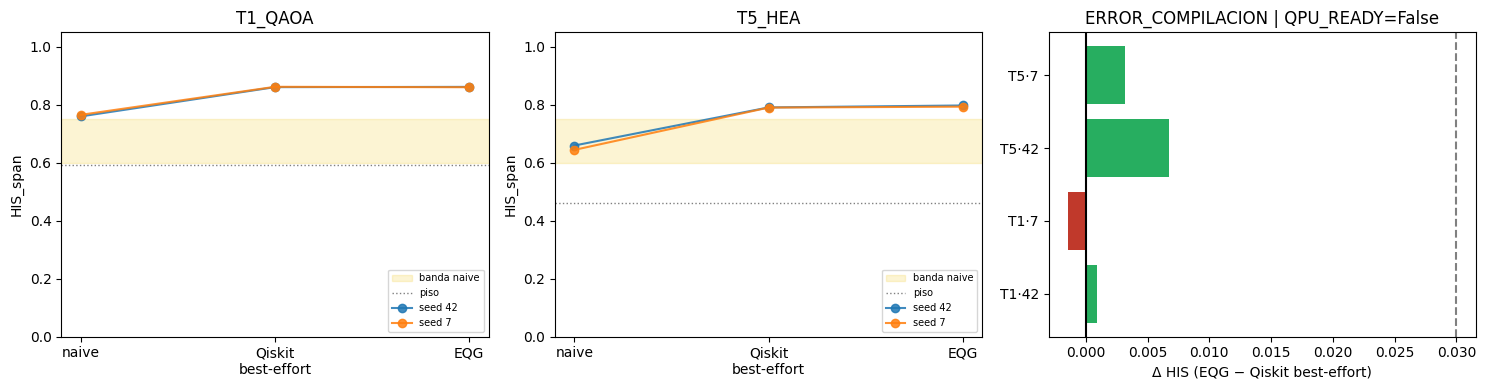

saved eqg_on_off_cpu/report_cpu.json


In [7]:
def agg(df, h, arm):
    sub = df[(df.H == h) & (df.arm == arm)]
    x = sub.HIS.to_numpy(float); se = sub.SE.to_numpy(float); k = len(x)
    se_s = math.sqrt(np.nansum(se ** 2)) / max(k, 1)
    se_b = float(np.std(x, ddof=1) / math.sqrt(k)) if k > 1 else 0.0
    return float(np.nanmean(x)), max(se_s, se_b), k

HS = ("T1_QAOA", "T5_HEA")
print("=" * 86)
print("  EQG vs Qiskit best-effort (opt=%d + DD) | %s | %s" % (QISKIT_OPT_LEVEL, EQG_VERSION, MODE))
print("  validez: NAIVE(T5) ∈ [%.2f, %.2f] | ganancia: ON−OFF(qiskit) z≥%.1f y Δ≥%.2f" % (BAND_LO, BAND_HI, Z_MIN, MIN_DELTA))
print("=" * 86)

per_seed, rows = {}, []
for sd, sc in SCEN.items():
    sub = df_all[df_all.seed == sd]
    v = {}
    for h in HS:
        mn, _, _ = agg(sub, h, "naive")
        mq, sq, kq = agg(sub, h, "qiskit")
        me, se_e, ke = agg(sub, h, "eqg")
        d = me - mq; z = z_diff(me, se_e, mq, sq)
        ok = bool(d > 0 and np.isfinite(z) and z >= Z_MIN and min(ke, kq) >= MIN_CYCLES_PER_ARM)
        v[h] = dict(HIS_naive=mn, HIS_qiskit=mq, HIS_eqg=me, delta=d, se_delta=math.sqrt(se_e**2 + sq**2), z=z,
                    pass_=ok, qiskit_gratis=mq - mn, eqg_total=me - mn, rescate=d / max(1.0 - mq, EPS),
                    floor=sc.HAM[h]["floor"])
        rows.append(dict(seed=sd, H=h, naive=mn, qiskit=mq, eqg=me, Qiskit_vs_naive=mq - mn,
                         EQG_vs_Qiskit=d, z=z, rescate=v[h]["rescate"], PASS=ok))
    base_ok = BAND_LO <= v["T5_HEA"]["HIS_naive"] <= BAND_HI
    per_seed[sd] = dict(v=v, base_ok=base_ok, compile_ok=sc.integ["ok"], issues=sc.integ["issues"],
                        qiskit_aware=sc.qiskit_noise_aware)

tab = pd.DataFrame(rows)
print(tab.round(4).to_string(index=False))
print("Qiskit_vs_naive = lo que Qiskit best-effort da gratis | EQG_vs_Qiskit = valor INCREMENTAL de EQG")
print("rescate = ΔEQG/(1−HIS_qiskit): fracción de la pérdida restante (tras Qiskit) que EQG recupera")

pooled = {}
for h in HS:
    d = np.array([per_seed[s]["v"][h]["delta"] for s in SEEDS])
    se = np.array([per_seed[s]["v"][h]["se_delta"] for s in SEEDS])
    md = float(d.mean()); sp = float(np.sqrt((se ** 2).sum()) / len(d))
    zp = md / sp if sp > EPS else float("nan")
    pooled[h] = dict(delta=md, se=sp, z=zp, min_delta=float(d.min()),
                     ok=bool(md >= MIN_DELTA and np.isfinite(zp) and zp >= Z_MIN and d.min() > 0),
                     regress=bool(md < 0 and np.isfinite(zp) and zp <= -Z_MIN))
    print("agregado %-8s EQG−Qiskit Δ=%+.4f ± %.4f z=%+.2f peor semilla Δ=%+.4f  %s" % (
        h, md, sp, zp, d.min(), "PASS" if pooled[h]["ok"] else ("REGRESIÓN" if pooled[h]["regress"] else "NO")))

compile_all = all(p["compile_ok"] for p in per_seed.values())
valid_all = all(p["base_ok"] for p in per_seed.values())
aware_all = all(p["qiskit_aware"] for p in per_seed.values())
sig_all = all(all(x["pass_"] for x in p["v"].values()) for p in per_seed.values())
pool_ok = all(p["ok"] for p in pooled.values())
regress = any(p["regress"] for p in pooled.values())

if not compile_all:
    gate = "ERROR_COMPILACION"; hint = "; ".join(i for p in per_seed.values() for i in p["issues"][:2])
elif not valid_all:
    gate = "PRUEBA_NO_VALIDA"
    offs = {s: round(p["v"]["T5_HEA"]["HIS_naive"], 3) for s, p in per_seed.items()}
    hint = "NAIVE(T5) fuera de [%.2f, %.2f]: %s → ajustar gate_x/idle_x mirando SOLO el naive" % (BAND_LO, BAND_HI, offs)
elif not aware_all:
    gate = "PRUEBA_NO_VALIDA"; hint = "el brazo Qiskit no fue noise-aware (Target sin errores): el comparador es débil, corregir antes de concluir"
elif regress:
    gate = "PRODUCTO_NO"; hint = "REGRESIÓN: EQG es peor que Qiskit best-effort con z≥2"
elif sig_all and pool_ok:
    gate = "PRODUCTO_OK"; hint = "EQG supera a Qiskit best-effort con z≥%.1f y Δ≥%.2f en todas las semillas, T1 y T5" % (Z_MIN, MIN_DELTA)
else:
    gate = "PRODUCTO_NO"
    hint = "PARIDAD: Qiskit best-effort ya captura casi todo el beneficio; EQG no aporta de forma significativa y material"

QPU_READY = bool(gate == "PRODUCTO_OK" and compile_all and valid_all and aware_all and pool_ok)
print("-" * 86)
print("Compilación íntegra       :", compile_all)
print("Estrés válido (naive banda):", valid_all)
print("Qiskit noise-aware        :", aware_all)
print("Veredicto                 :", gate, "|", hint)
print("QPU_READY                 :", QPU_READY)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, h in enumerate(HS):
    ax = axes[i]
    ax.axhspan(BAND_LO, BAND_HI, color="#f1c40f", alpha=0.18, label="banda naive")
    ax.axhline(per_seed[SEEDS[0]]["v"][h]["floor"], color="gray", ls=":", lw=1, label="piso")
    for sd in SEEDS:
        v = per_seed[sd]["v"][h]
        ax.plot([0, 1, 2], [v["HIS_naive"], v["HIS_qiskit"], v["HIS_eqg"]], "-o", alpha=0.85, label="seed %d" % sd)
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["naive", "Qiskit\nbest-effort", "EQG"])
    ax.set_ylim(0, 1.05); ax.set_ylabel("HIS_span"); ax.set_title(h); ax.legend(fontsize=7, loc="lower right")
ax = axes[2]
labs = ["%s·%d" % (h[:2], s) for h in HS for s in SEEDS]
vals = [per_seed[s]["v"][h]["delta"] for h in HS for s in SEEDS]
ax.barh(labs, vals, color=["#27ae60" if x > 0 else "#c0392b" for x in vals])
ax.axvline(0, color="k"); ax.axvline(MIN_DELTA, color="gray", ls="--")
ax.set_xlabel("Δ HIS (EQG − Qiskit best-effort)"); ax.set_title("%s | QPU_READY=%s" % (gate, QPU_READY))
plt.tight_layout()
fig.savefig(OUT / "eqg_vs_qiskit.png", dpi=140, bbox_inches="tight")
plt.show()

report = dict(
    version=EQG_VERSION, fingerprint=FP, mode=MODE, gate=gate, hint=hint, QPU_READY=QPU_READY,
    criteria=dict(band_naive=[BAND_LO, BAND_HI], z_min=Z_MIN, min_delta=MIN_DELTA,
                  min_cycles=MIN_CYCLES_PER_ARM, qiskit_opt_level=QISKIT_OPT_LEVEL),
    compile_ok=compile_all, naive_in_band=valid_all, qiskit_noise_aware=aware_all, pooled=pooled,
    per_seed={str(s): dict(base_ok=p["base_ok"], compile_ok=p["compile_ok"], issues=p["issues"],
                           verdict=p["v"], motor=SCEN[s].motor,
                           layouts=dict(naive=SCEN[s].layout_base, qiskit=getattr(SCEN[s], "layout_qiskit", None),
                                        eqg=SCEN[s].layout_eqg),
                           thresholds=dict(layout=SCEN[s].layout_thr, dd=SCEN[s].dd_thr),
                           dd_qubits=SCEN[s].dd_q, dd_route=sorted(SCEN[s].dd_route),
                           equiv={"%s/%s" % k: v for k, v in SCEN[s].integ["equiv"].items()},
                           compiled=SCEN[s].integ["table"].to_dict(orient="records"))
              for s, p in per_seed.items()},
    load=dict(N=N, qaoa_p=QAOA_P, hea_layers=HEA_LAYERS, idle_us=IDLE_US, shots=SHOTS,
              cycles_per_arm=N_CYCLES, k_real=K_REAL, sim=SIM),
    records=df_all.to_dict(orient="records"),
    created=time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
)
path = OUT / f"report_{MODE}.json"
path.write_text(json.dumps(report, indent=2, default=lambda o: float(o) if hasattr(o, "item") else str(o)))
tab.to_csv(OUT / "per_seed_table.csv", index=False)
(OUT / "summary.txt").write_text("gate=%s\nQPU_READY=%s\n%s\n" % (gate, QPU_READY, tab.round(4).to_string(index=False)))
print("saved", path)


## Cómo leer el resultado

- **`Qiskit_vs_naive`**: lo que Qiskit best-effort da gratis. **`EQG_vs_Qiskit`**: el valor incremental real de EQG.
- **`PRODUCTO_NO` por paridad**: Qiskit ya recupera casi todo; el argumento comercial de EQG no puede ser “mejor layout” y debe apoyarse en lo que Qiskit no hace (telemetría viva, abortar cuando el dispositivo está mal, ahorro de QPU) → medirlo en hardware.
- **`ERROR_COMPILACION`**: bug del producto, no del hardware; no gastar QPU.
- **`PRUEBA_NO_VALIDA`**: ajustar `gate_x`/`idle_x` mirando solo `naive`, congelar y repetir.

**Límites:** el idle solo acumula en ventanas `delay` explícitas; la desintonía cuasi-estática es un modelo; el DD en CPU es CPMG manual (en QPU, `PadDynamicalDecoupling` con la ruta reportada); la calibración “obsoleta” que ve Qiskit es ±22 % de la viva — el hardware real puede diferir más. La rama QPU no está probada.

Copyright (c) 2026 Arturo Salvador Balderas Hernández — Elastic License 2.0. Qiskit Apache-2.0. `EQG-1.3.0`.
